# Compute the potential-field data

Compute the potential-field data produced by the geological source simulated in the notebook `1_model.ipynb`.

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
import time

In [5]:
import pickle

In [6]:
from gravmag import data_structures, utils, aux_vedo, constants
from gravmag.models import rectangular_prism as rp

In [7]:
import vedo

In [8]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Load the model

In [9]:
boundary_points = pickle.load(open('model_boundary_points.pickle', 'rb'))

In [10]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [11]:
model = pickle.load(open('model/model.pickle', 'rb'))

In [12]:
model_area = pickle.load(open('model/model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/model_shape.pickle', 'rb'))

In [13]:
mag_intensity = pickle.load(open('model/model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/model_mag_dec.pickle', 'rb'))

In [14]:
# model properties
print("(xmin, xmax) = ({:.3f}, {:.3f}) m".format(model['x1'].min(), model['x2'].max()))
print("(ymin, ymax) = ({:.3f}, {:.3f}) m".format(model['y1'].min(), model['y2'].max()))
print("(top min, top max) = ({:.3f}, {:.3f}) m".format(model['z1'].min(), model['z1'].max()))
print("(bottom min, bottom max) = ({:.3f}, {:.3f}) m".format(model['z2'].min(), model['z2'].max()))
print("number of prisms: {}".format(model['x1'].size))

(xmin, xmax) = (-3600.986, 4900.000) m
(ymin, ymax) = (-3000.333, 5800.167) m
(top min, top max) = (0.000, 300.000) m
(bottom min, bottom max) = (300.001, 600.001) m
number of prisms: 1241


In [15]:
# compute the Cartesian components of magnetization
mx, my, mz = utils.magnetization_components(
    np.vstack([mag_intensity, mag_inc, mag_dec]).T
)

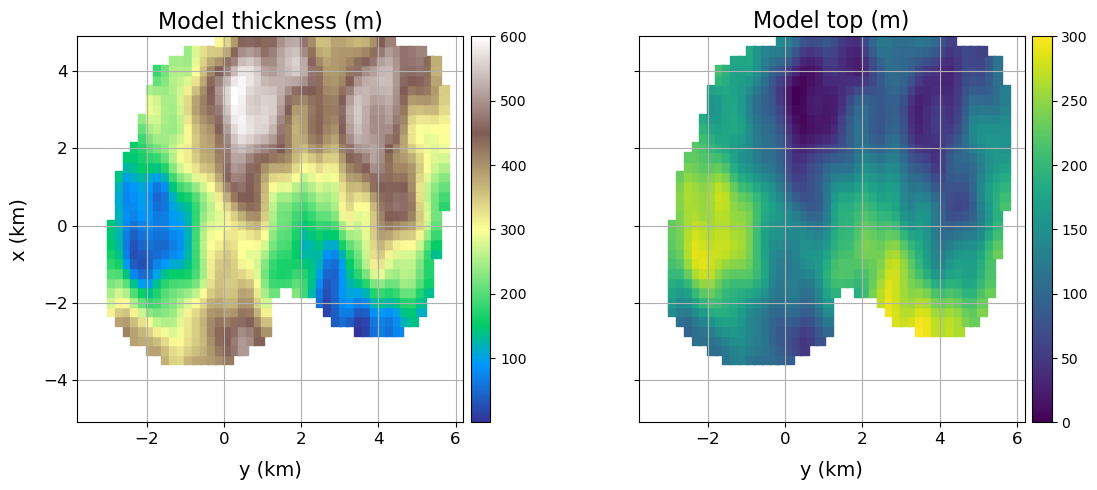

In [16]:
fig, axs = plt.subplots(
    ncols=2, nrows=1, 
    sharex=False, sharey=True,
    figsize=(12, 5), 
)

axs[0].set_title("Model thickness (m)", fontsize=16)
axs[0].axis('scaled')
image = axs[0].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z2']-model['z1'],
    marker='s',
    cmap='terrain'
)
axs[0].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[0].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[0].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[0])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[0].grid()
axs[0].set_ylabel('x (km)', fontsize=14, labelpad=10)
axs[0].set_xlabel('y (km)', fontsize=14, labelpad=10)

axs[1].set_title("Model top (m)", fontsize=16)
axs[1].axis('scaled')
image = axs[1].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z1'],
    marker='s',
    cmap='viridis'
)
axs[1].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[1].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[1].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[1])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[1].grid()
axs[1].set_xlabel('y (km)', fontsize=14, labelpad=10)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.30, hspace=0.05)

plt.tight_layout()

plt.show()

### 3D Plot

In [17]:
# create a Vedo model of prisms with colors defined by the total-magnetization intensity
model_vedo = aux_vedo.gravmag2vedo_prisms(
    gravmag_prisms=model,
    scalar_props=mag_intensity,
    cmap='jet',
    vmin=np.min(mag_intensity),
    vmax=np.max(mag_intensity)
)


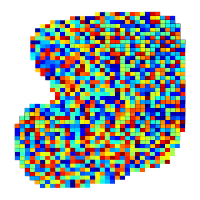

In [18]:
# add a colorbar to the prisms
model_vedo.add_scalarbar(
    title='magnetization (A/m)', 
    pos=(0.8,0.01),
    title_yoffset=15,
    font_size=14,
    nlabels=10,
    horizontal=False,
    label_format=':6.2f'
)

### Main field

In [19]:
main_field = pickle.load(open('model/main_field.pickle', 'rb'))

In [20]:
# Cartesian components of the main field
Fx_hat, Fy_hat, Fz_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

### Points were we compute the synthetic data

In [21]:
# number of points along x and y
data_shape = (400, 330)
print('n. data = {}'.format(data_shape[0]*data_shape[1]))

# minimum x, maximum x, minimum y and maximum y
data_area = [-7100, 7500, -4800, 7200]

# grid spacing
data_dx, data_dy = data_structures.grid_xy_spacing(area=data_area, shape=data_shape)
print('dx = {:.3f} m | dy = {:.3f} m'.format(data_dx, data_dy))

n. data = 132000
dx = 36.591 m | dy = 36.474 m


In [22]:
coordinates_grid = pickle.load(open('model/coordinates_grid.pickle', 'rb'))

In [23]:
print('num. data points = {}'.format(coordinates_grid['shape'][0]*coordinates_grid['shape'][1]))

num. data points = 132000


### Synthetic data

In [24]:
U = pickle.load(open('model/pseudo_potential.pickle', 'rb'))

In [25]:
pseudo_grav = pickle.load(open('model/pseudo_grav.pickle', 'rb'))

In [26]:
V = pickle.load(open('model/magnetic_potential.pickle', 'rb'))

In [27]:
bx = pickle.load(open('model/magnetic_field_component_bx.pickle', 'rb'))
by = pickle.load(open('model/magnetic_field_component_by.pickle', 'rb'))
bz = pickle.load(open('model/magnetic_field_component_bz.pickle', 'rb'))

In [28]:
b_amp = np.sqrt(bx**2 + by**2 + bz**2)

# Compute the approximated total-field anomaly (Blakely, 1996, p. 179)
approx_tfa = Fx_hat*bx + Fy_hat*by + Fz_hat*bz

In [29]:
rtp = pickle.load(open('model/rtp.pickle', 'rb'))

# Plot the data

In [30]:
# coordinates rearranged for plotting
# they are "views' of the original coordinates in 'coordinates_grid'
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

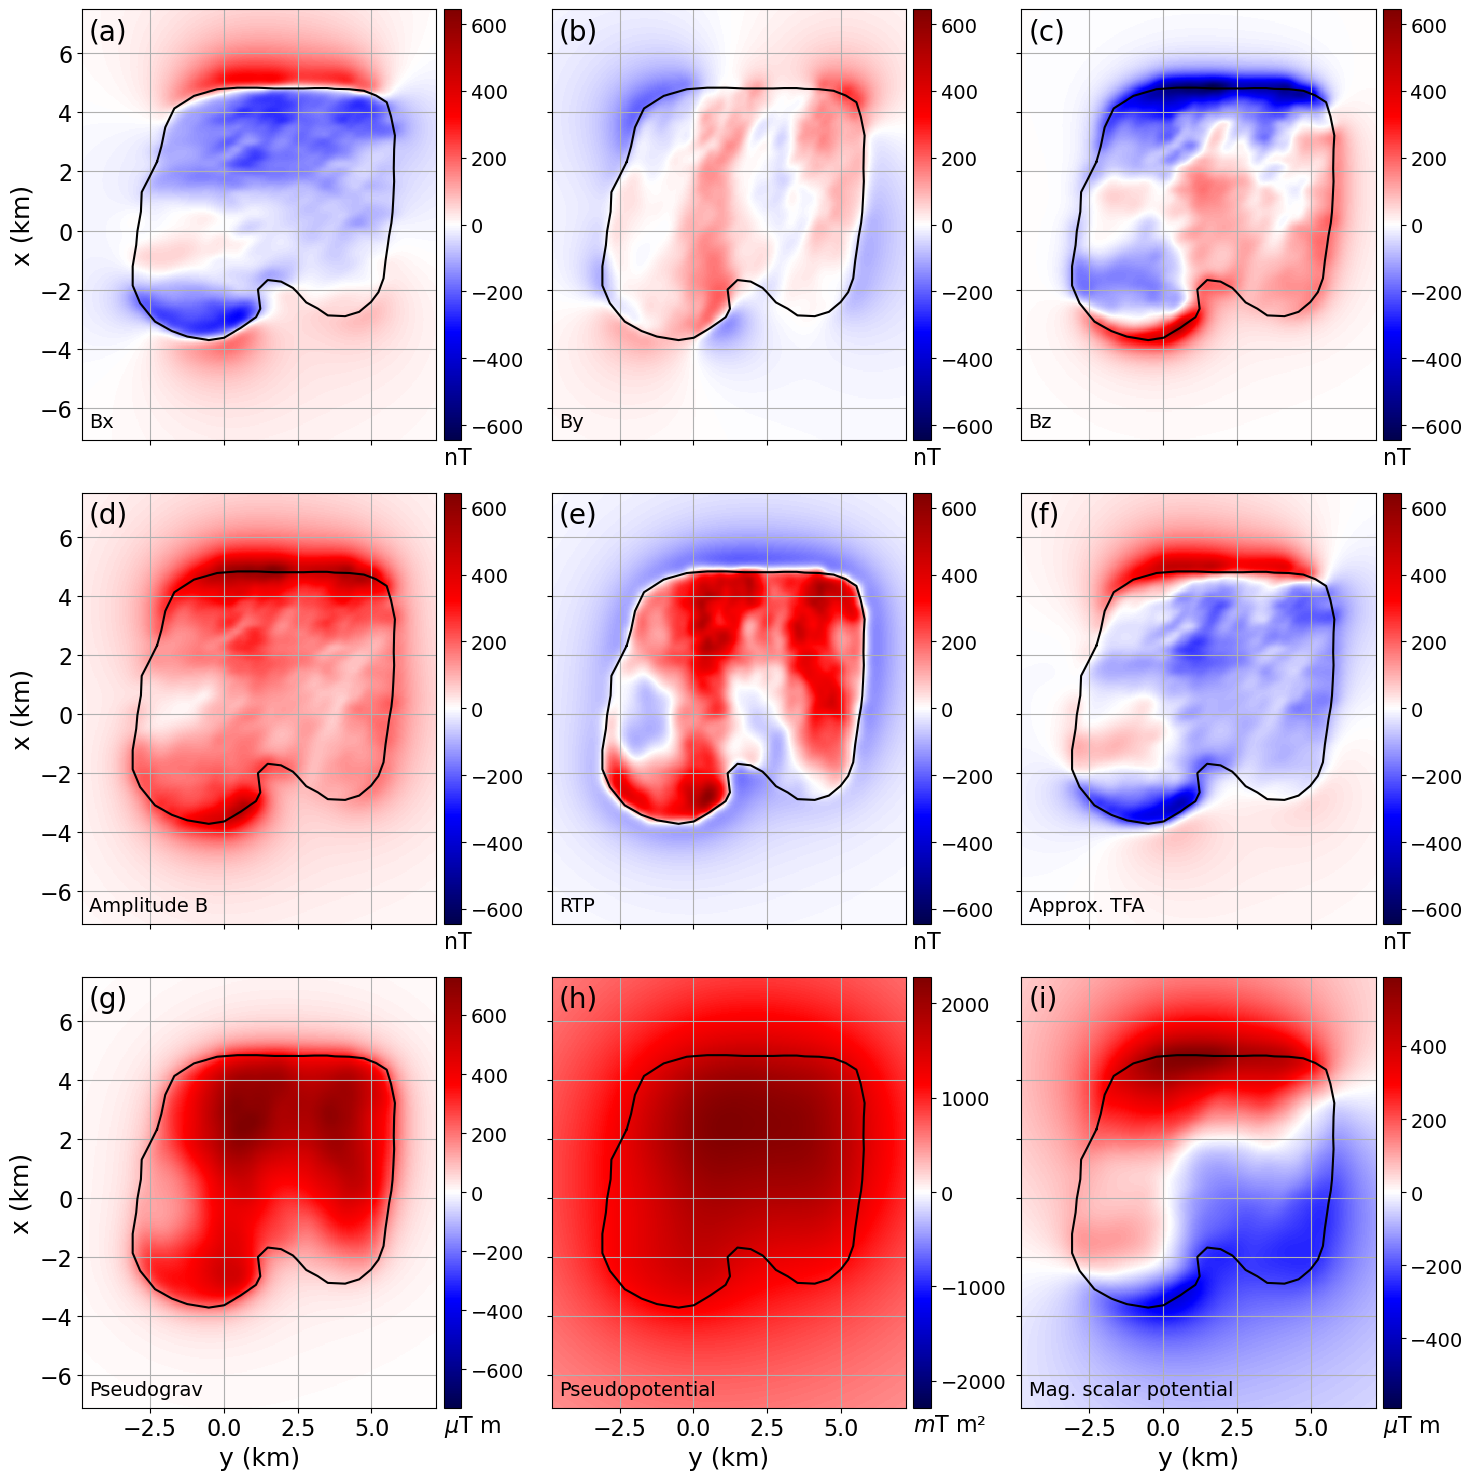

In [31]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,15)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)', '(h)', '(i)']

mosaic_elements = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i']

titles = [
    'Bx', 'By', 'Bz',
    'Amplitude B', 'RTP', 'Approx. TFA',
    'Pseudograv', 'Pseudopotential', 'Mag. scalar potential'
]

units = 6*['nT'] + ['$\mu$T m'] + ['$m$T m²'] + ['$\mu$T m']

ranges_b = np.max(np.abs([bx, by, bz, b_amp, rtp, approx_tfa]))
ranges_pseudo_grav = np.max(np.abs(pseudo_grav))
ranges_U = np.max(np.abs(U))
ranges_V = np.max(np.abs(V))
ranges = 6*[ranges_b] + [ranges_pseudo_grav] + [ranges_U] + [ranges_V]

for (element, field, label, ranges_field, unit, title) in zip(
    mosaic_elements, 
    [bx, by, bz, b_amp, rtp, approx_tfa, pseudo_grav, U, V], 
    labels,
    ranges,
    units,
    titles
):
    ax = mosaic[element]
    ax.axis('scaled')
    im = ax.pcolormesh(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=field,
            ordering='xy',
            shape=coordinates_grid['shape']
        ),
        cmap='seismic', vmin=-ranges_field, vmax=ranges_field
    )
    ax_divider = make_axes_locatable(ax)
    cax = ax_divider.append_axes("right", size="5%", pad="2%")
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(labelsize=14)
    cb.ax.set_xlabel(unit, fontsize=16, loc='left')
    ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
    ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid()
    ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
    ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['g','h','i']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)  

plt.show()